# Rakshak AI — Synthetic Vibration EDA

This notebook validates the feature-extraction pipeline before real datasets
(CWRU bearing dataset) are integrated in Phase 2 (see `docs/FutureRoadmap.md`).

It generates synthetic "healthy" and "faulty" bearing vibration signals,
extracts statistical and frequency-domain features, and visually checks
whether those features separate the two classes — the same logic used in
`models/train_baseline.py`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = np.random.default_rng(seed=42)
SAMPLE_RATE_HZ = 2000
WINDOW_SECONDS = 1.0
N_SAMPLES = int(SAMPLE_RATE_HZ * WINDOW_SECONDS)


## 1. Synthetic signal generator

Healthy = clean sine wave + low noise. Faulty = same sine wave + periodic high-frequency impulses + higher noise.

In [2]:
def generate_window(is_faulty: bool) -> np.ndarray:
    t = np.arange(N_SAMPLES) / SAMPLE_RATE_HZ
    base_freq_hz = 50.0
    signal = np.sin(2 * np.pi * base_freq_hz * t)

    noise_level = 0.05 if not is_faulty else 0.15
    signal += RNG.normal(0, noise_level, size=signal.shape)

    if is_faulty:
        impulse_freq_hz = 300.0
        impulse_positions = np.arange(0, N_SAMPLES, int(SAMPLE_RATE_HZ / impulse_freq_hz))
        impulse = np.zeros(N_SAMPLES)
        impulse[impulse_positions] = RNG.uniform(0.8, 1.5, size=len(impulse_positions))
        signal += impulse
    return signal

healthy_signal = generate_window(is_faulty=False)
faulty_signal = generate_window(is_faulty=True)


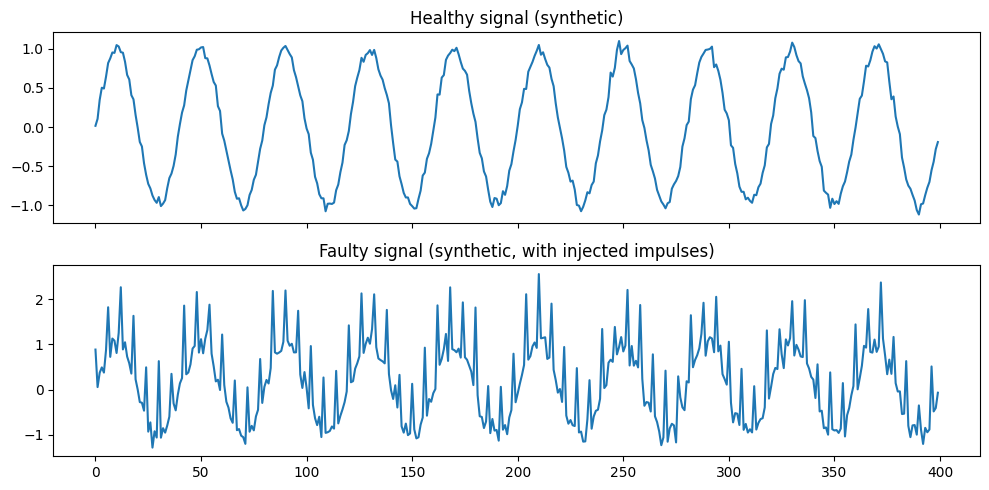

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(healthy_signal[:400])
axes[0].set_title("Healthy signal (synthetic)")
axes[1].plot(faulty_signal[:400])
axes[1].set_title("Faulty signal (synthetic, with injected impulses)")
plt.tight_layout()
plt.savefig("synthetic_signal_comparison.png", dpi=100)
plt.show()


## 2. Feature extraction

Same logic as `models/train_baseline.py`, kept in sync deliberately.

In [4]:
def extract_features(signal: np.ndarray) -> dict:
    fft_vals = np.abs(np.fft.rfft(signal))
    freqs = np.fft.rfftfreq(len(signal), d=1.0 / SAMPLE_RATE_HZ)
    high_band_mask = freqs > 200
    high_band_energy = fft_vals[high_band_mask].sum()

    mean = signal.mean()
    std = signal.std()
    rms = np.sqrt(np.mean(signal ** 2))
    kurtosis = (((signal - mean) ** 4).mean()) / (std ** 4 + 1e-9)
    crest_factor = np.max(np.abs(signal)) / (rms + 1e-9)

    return {"rms": rms, "kurtosis": kurtosis, "crest_factor": crest_factor, "high_band_energy": high_band_energy}

rows = []
for _ in range(300):
    rows.append({**extract_features(generate_window(False)), "label": "healthy"})
for _ in range(60):
    rows.append({**extract_features(generate_window(True)), "label": "faulty"})

df = pd.DataFrame(rows)
df.groupby("label").mean()


,rms,kurtosis,crest_factor,high_band_energy
label,,,,
faulty,0.866622,2.396671,3.040582,7714.490648
healthy,0.708721,1.514834,1.607073,1586.007900


## 3. Does `high_band_energy` separate healthy vs. faulty?

This is the feature we expect to matter most, since faults were injected as high-frequency impulses.

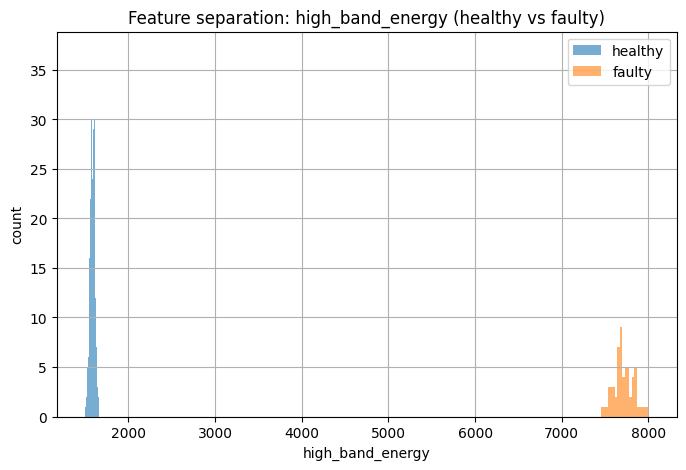

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
df[df.label == "healthy"]["high_band_energy"].hist(alpha=0.6, label="healthy", bins=20, ax=ax)
df[df.label == "faulty"]["high_band_energy"].hist(alpha=0.6, label="faulty", bins=20, ax=ax)
ax.set_xlabel("high_band_energy")
ax.set_ylabel("count")
ax.legend()
ax.set_title("Feature separation: high_band_energy (healthy vs faulty)")
plt.savefig("feature_separation.png", dpi=100)
plt.show()


## 4. Conclusion

`high_band_energy` and `kurtosis` show visible separation between healthy
and faulty synthetic windows, which is why these are the features used in
`models/train_baseline.py`'s `IsolationForest` baseline.

**Important caveat:** this is synthetic data designed to be separable. It
validates that the pipeline (signal → features → model) works mechanically.
It does **not** validate real-world detection performance. Phase 2 replaces
this synthetic generator with the CWRU bearing dataset — see
`docs/FutureRoadmap.md`.
